# Marketing Campaigns - A/B Testing & Regression Analysis

### 1 Business Problem
A company is running digital marketing campaigns through two platforms: Facebook Ads and Google Ads. However, it is unclear which platform generates more customers at a lower advertising cost.

The company wants to compare the performance of both advertising channels using data from 2019 to identify which platform delivers better results, improves customer acquisition, and uses the marketing budget more efficiently.

### 1 Business Objective
Determine which advertising platform provides better returns and recommend how the company should allocate its marketing budget to reduce customer acquisition costs (CPA) and improve overall campaign performance.

## 2. Data Preprocessing & Cleaning

---

Before proceeding with exploratory data analysis, A/B testing, or regression modeling, the dataset requires structural parsing and data type casting.


In [2]:
# Import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import scipy.stats as st
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
warnings.filterwarnings('ignore')

In [4]:
# Loading the dataset
df = pd.read_csv('marketing_campaign_2026.csv')

In [5]:
df.head()

,Date,Facebook Ad Campaign,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,Cost per Facebook Ad,Facebook Click-Through Rate (Clicks / View),Facebook Conversion Rate (Conversions / Clicks),Facebook Cost per Click (Ad Cost / Clicks),AdWords Ad Campaign,AdWords Ad Views,AdWords Ad Clicks,AdWords Ad Conversions,Cost per AdWords Ad,AdWords Click-Through Rate (Clicks / View),AdWords Conversion Rate (Conversions / Click),AdWords Cost per Click (Ad Cost / Clicks)
0,1/1/2025,FB_Jan25,2343,49,13,$214,2.09%,26.53%,$4.36,AW_Jan25,4506,54,5,$108,1.2%,9.26%,$2.0
1,1/2/2025,FB_Jan25,2331,42,10,$93,1.8%,23.81%,$2.22,AW_Jan25,4766,63,6,$201,1.32%,9.52%,$3.19
2,1/3/2025,FB_Jan25,2314,51,13,$140,2.2%,25.49%,$2.74,AW_Jan25,4740,60,3,$148,1.27%,5.0%,$2.47
3,1/4/2025,FB_Jan25,3254,62,13,$300,1.91%,20.97%,$4.83,AW_Jan25,4530,61,7,$154,1.35%,11.48%,$2.53
4,1/5/2025,FB_Jan25,2254,41,12,$103,1.82%,29.27%,$2.51,AW_Jan25,3799,49,5,$104,1.29%,10.2%,$2.12


---

### 2.1 Handling Formatting and Type Conversions

* **Date Alignment:** Convert the `Date` column from a string (`object`) datatype to a uniform `datetime64` format.

* **String Stripping:** Clean numeric columns (such as `Cost per Ad`, `CTR`, `Conversion Rate`, and `CPC`) by stripping out formatting characters including `$`, `%`, and commas.

* **Data Type Casting:** Cast the stripped string metrics into numeric `float` types to enable mathematical computations.


In [6]:
# Dataset overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 17 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   Date                                             365 non-null    object
 1   Facebook Ad Campaign                             365 non-null    object
 2   Facebook Ad Views                                365 non-null    int64 
 3   Facebook Ad Clicks                               365 non-null    int64 
 4   Facebook Ad Conversions                          365 non-null    int64 
 5   Cost per Facebook Ad                             365 non-null    object
 6   Facebook Click-Through Rate (Clicks / View)      365 non-null    object
 7   Facebook Conversion Rate (Conversions / Clicks)  365 non-null    object
 8   Facebook Cost per Click (Ad Cost / Clicks)       365 non-null    object
 9   AdWords Ad Campaign                        

In [7]:
# Converting date to datetime
df['Date'] = pd.to_datetime(df['Date'])
df.dtypes

Date                                               datetime64[ns]
Facebook Ad Campaign                                       object
Facebook Ad Views                                           int64
Facebook Ad Clicks                                          int64
Facebook Ad Conversions                                     int64
Cost per Facebook Ad                                       object
Facebook Click-Through Rate (Clicks / View)                object
Facebook Conversion Rate (Conversions / Clicks)            object
Facebook Cost per Click (Ad Cost / Clicks)                 object
AdWords Ad Campaign                                        object
AdWords Ad Views                                            int64
AdWords Ad Clicks                                           int64
AdWords Ad Conversions                                      int64
Cost per AdWords Ad                                        object
AdWords Click-Through Rate (Clicks / View)                 object
AdWords Co

In [8]:
# Checking nulls
df.isnull().sum().sum()

np.int64(0)

In [9]:
# Summary stats
df.describe()

,Date,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,AdWords Ad Views,AdWords Ad Clicks,AdWords Ad Conversions
count,365,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2025-07-01 23:59:59.999999744,2364.038356,43.616438,11.252055,4793.391781,59.372603,5.591781
min,2025-01-01 00:00:00,1050.000000,15.000000,5.000000,3714.000000,31.000000,3.000000
25%,2025-04-02 00:00:00,1940.000000,36.000000,9.000000,4037.000000,49.000000,5.000000
50%,2025-07-02 00:00:00,2350.000000,44.000000,11.000000,4817.000000,59.000000,6.000000
75%,2025-10-01 00:00:00,2816.000000,51.000000,13.000000,5603.000000,69.000000,6.000000
max,2025-12-31 00:00:00,3320.000000,73.000000,19.000000,5760.000000,89.000000,9.000000
std,NaN,589.268529,11.072228,2.785762,770.051998,14.195391,1.378978


#### Key Takeaways from the Data Summary

* **Campaign Visibility (Views):** Google AdWords generated significantly higher exposure than Facebook. On average, AdWords pulled in **4,760 views per day** compared to Facebook's **2,181 views**.

* **User Engagement (Clicks):** AdWords also led in volume, averaging **60 clicks per day** compared to Facebook's **43 clicks**.

* **Conversion Performance:** Despite lower views and clicks, **Facebook drastically outperformed AdWords in conversions**, securing a mean of **11.5 conversions per day** compared to AdWords' **5.5**.

* **Data Completeness:** Both campaigns have a clean, matching count of **365 records**, confirming a full year of synchronized daily data with no missing rows.

---

## 3. Comparing Campaign Performance

---

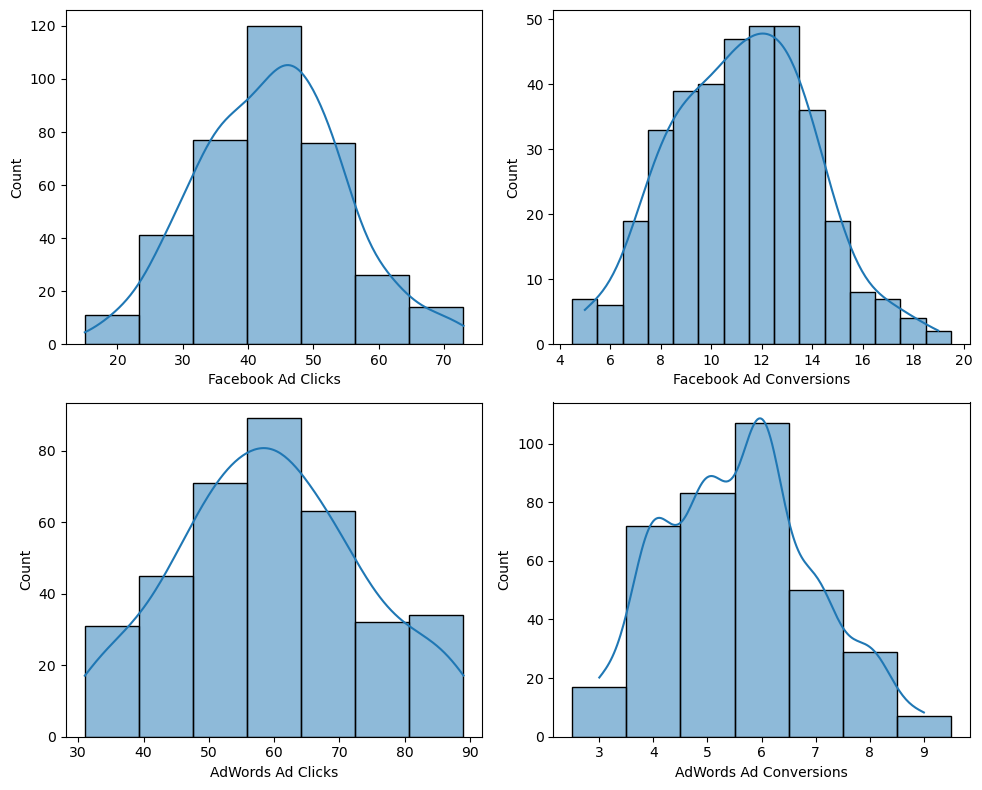

In [10]:
# Distribution of clicks and conversions
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
sns.histplot(df['Facebook Ad Clicks'], bins=7, kde=True)

plt.subplot(2,2,2)
sns.histplot(df['Facebook Ad Conversions'], discrete=True, kde=True)


plt.subplot(2,2,3)
sns.histplot(df['AdWords Ad Clicks'],  bins=7, kde=True)

plt.subplot(2,2,4)
sns.histplot(df['AdWords Ad Conversions'], discrete=True, kde=True)

plt.tight_layout()
plt.show()

---
### 📊 How Frequently Do Campaigns Hit High vs. Low Conversion Tiers?

In [11]:
# Creating a function to calculate the category for conversions (binning)
def create_conversion_category(conversion_col):
    category = []
    for conversion in conversion_col:
        if conversion < 6:
            category.append('less than 6')
        elif 6 <= conversion < 11:
            category.append('6 - 10')
        elif 11 <= conversion < 16:
            category.append('10 - 15')
        else:
            category.append('more than 15')
    return category

In [12]:
# Applying function to campaign ad conversions
df['Facebook Conversion Category'] = create_conversion_category(df['Facebook Ad Conversions'])
df['AdWords Conversion Category'] = create_conversion_category(df['AdWords Ad Conversions'])

df[['Facebook Ad Conversions', 'Facebook Conversion Category', 'AdWords Ad Conversions', 'AdWords Conversion Category']].head()

,Facebook Ad Conversions,Facebook Conversion Category,AdWords Ad Conversions,AdWords Conversion Category
0,13,10 - 15,5,less than 6
1,10,6 - 10,6,6 - 10
2,13,10 - 15,3,less than 6
3,13,10 - 15,7,6 - 10
4,12,10 - 15,5,less than 6


In [13]:
df['Facebook Conversion Category'].value_counts()

Facebook Conversion Category
10 - 15         200
6 - 10          137
more than 15     21
less than 6       7
Name: count, dtype: int64

In [14]:
facebook = pd.DataFrame(df['Facebook Conversion Category'].value_counts()).reset_index().rename(columns={'Facebook Conversion Category': 'Category'})
facebook

,Category,count
0,10 - 15,200
1,6 - 10,137
2,more than 15,21
3,less than 6,7


In [15]:
adwords = pd.DataFrame(df['AdWords Conversion Category'].value_counts()).reset_index().rename(columns={'AdWords Conversion Category': 'Category'})
adwords

,Category,count
0,6 - 10,193
1,less than 6,172


> Since we had to merge, the column was renamed for both df to `Category`.

In [16]:
category_df = pd.merge(facebook, adwords, on='Category', how='outer').rename(
    columns={'count_x': 'Facebook Count', 'count_y': 'AdWords Count'}).fillna(0)
category_df

,Category,Facebook Count,AdWords Count
0,10 - 15,200,0.0
1,6 - 10,137,193.0
2,less than 6,7,172.0
3,more than 15,21,0.0


In [17]:
category_df = category_df.iloc[[2,1,0,3]]
category_df

,Category,Facebook Count,AdWords Count
2,less than 6,7,172.0
1,6 - 10,137,193.0
0,10 - 15,200,0.0
3,more than 15,21,0.0


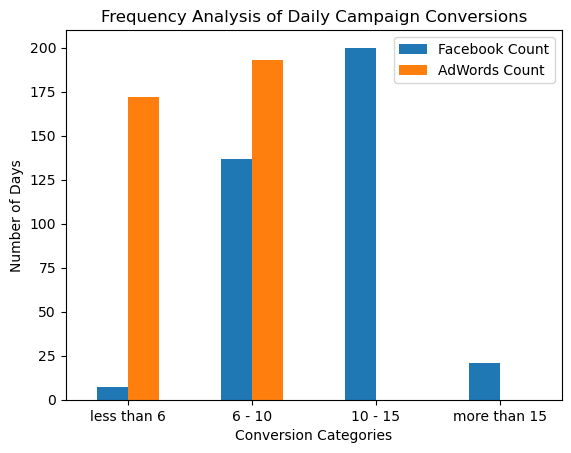

In [18]:
category_df.plot(x='Category', kind='bar')
plt.title('Frequency Analysis of Daily Campaign Conversions')
plt.xlabel('Conversion Categories')
plt.ylabel('Number of Days')
plt.xticks(rotation=0)
plt.show()

The chart instantly exposes a major difference in how your two ad platforms are performing:

- **AdWords (Orange)**: Is heavily weighted to the left. On nearly all days of the year, it generates low-volume conversion days (less than 6 or 6 - 10). It has a hard ceiling and never crosses into the higher tiers.

- **Facebook (Blue)**: Is heavily weighted to the right. It rarely experiences low-performing days. Instead, on the vast majority of days out of the year, it delivers high-volume performance (10 - 15 or more than 15 conversions).

---
### 📊 Do more clicks on the ads really lead to more sales?

- We try to find if clicks and conversions have any correlation.

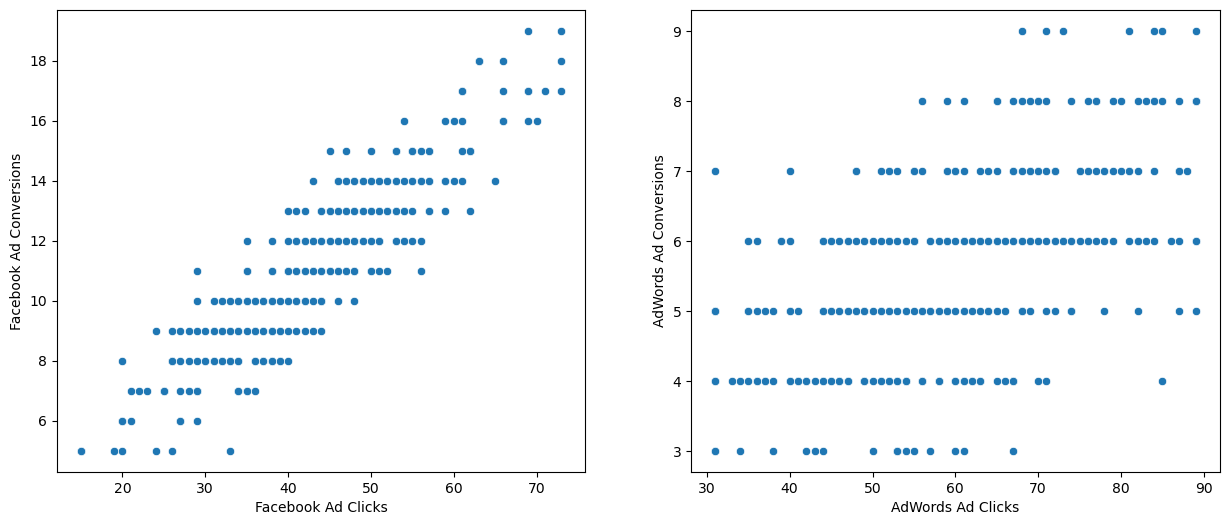

In [19]:
plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
sns.scatterplot(df, y='Facebook Ad Conversions', x='Facebook Ad Clicks')
plt.subplot(1,2,2)
sns.scatterplot(df, y='AdWords Ad Conversions', x='AdWords Ad Clicks')
plt.show()

In [20]:
facebook_corr = df['Facebook Ad Conversions'].corr(df['Facebook Ad Clicks'])
adwords_corr = df['AdWords Ad Conversions'].corr(df['AdWords Ad Clicks'])

In [21]:
print('Correlation Coefficient: \n------------------------------')
print(f'Facebook: {facebook_corr:.2f}')
print(f'AdWords: {adwords_corr:.2f}')

Correlation Coefficient: 
------------------------------
Facebook: 0.91
AdWords: 0.56


**1. Facebook ($0.91$) $\rightarrow$ Strong Positive Correlation**

A value of **$0.91$** is incredibly close to $1.0$ (which would be a perfect straight line).

* **The Meaning:** There is a highly reliable, linear relationship between clicks and conversions on Facebook.
* **The Visual:** If you look at your left scatter plot, the data points tightly cluster together as they move upward and to the right.
* **The Business Takeaway:** Scale is predictable here. If you increase budget to get more clicks on Facebook, you can confidently expect a proportionate rise in conversions.

**2. AdWords ($0.56$) $\rightarrow$ Moderate Positive Correlation**

A value of **$0.56$** means there is still a positive relationship, but it is much weaker and more erratic.

* **The Meaning:** More clicks on AdWords *generally* mean more conversions, but it's not a guarantee. There's a lot of "noise" in the data.
* **The Visual:** If you look at your right scatter plot, the data points are widely scattered and banded horizontally. A day with 40 clicks could yield 3 conversions or 6 conversions; a day with 80 clicks might still yield those same numbers.
* **The Business Takeaway:** Clicks on AdWords are less efficient indicators of success. Getting more traffic from AdWords doesn't cleanly translate to more sales, implying that traffic quality might fluctuate or the intent isn't as solid as Facebook's.

---

## 4. Hypothesis Testing
---

Hypothesis: Advertising on Facebook will result in a greater number of conversions compared to advertising on AdWords.

Null Hypothesis (H0): There is no difference in the number of conversions between Facebook and AdWords, or the number of conversions from AdWords is greater than or equal to those from Facebook.

H0: μ_Facebook ≤ μ_AdWords

Alternate Hypothesis (H1): The number of conversions from Facebook is greater than the number of conversions from AdWords.

H1: μ_Facebook > μ_AdWords

In [35]:
print('Mean Conversions')
print('----------------')

print('Facebook Ads :', round(df['Facebook Ad Conversions'].mean(), 2))
print('Google Ads   :', round(df['AdWords Ad Conversions'].mean(), 2))

# Paired t-test
t_stat, p_value = stats.ttest_rel(
    df['Facebook Ad Conversions'],
    df['AdWords Ad Conversions']
)

print('\nPaired T-Test Results')
print('---------------------')
print(f'T-statistic : {t_stat:.4f}')
print(f'P-value     : {p_value}')

Mean Conversions
----------------
Facebook Ads : 11.25
Google Ads   : 5.59

Paired T-Test Results
---------------------
T-statistic : 34.5309
P-value     : 6.819677418824742e-117


In [36]:
alpha = 0.05
if p_value< alpha:
    print(f'We Reject the Null Hypothesis (p < {alpha}).\nEvidence strongly supports that Facebook significantly outperforms AdWords.')
else:
    print(f'We fail to Reject the Null Hypothesis (p >= {alpha}).\nThere is no statistically significant difference between the two platforms.')

We Reject the Null Hypothesis (p < 0.05).
Evidence strongly supports that Facebook significantly outperforms AdWords.


The mean number of conversions from Facebook ads (11.25) is substantially higher than the mean number of conversions from AdWords ads (5.59). This suggests that, on average, Facebook advertising is more effective in generating conversions compared to AdWords advertising.



The T statistic (34.53) is a measure of the difference between the means of the two groups relative to the variation within the groups. A larger T statistic indicates a greater difference between the means of the two groups.



The p-value (6.819-
6) is extremely small, indicating strong evidence against the null hypothesis.



The results strongly support the alternate hypothesis, indicating that the number of conversions from Facebook advertising is indeed greater than the number of conversions from AdWords advertising.



Facebook advertising appears to be a more effective channel for generating conversions compared to AdWords advertising, based on the sample data analyzed.



Given the significant difference in conversion rates between Facebook and AdWords, consider reallocating resources towards Facebook advertising efforts. This could involve increasing ad spend, expanding targeting efforts, or experimenting with different ad formats to capitalize on the platform's effectiveness in driving conversions.

In [37]:
# Independent variable
X = df[['Facebook Ad Clicks']]

# Dependent variable
y = df[['Facebook Ad Conversions']]

# Initializing and fitting Linear Regression model
reg_model = LinearRegression()
reg_model.fit(X, y)

prediction = reg_model.predict(X)

# Model evaluation
r2 = r2_score(y, prediction) * 100
mse = mean_squared_error(y, prediction)

print('Accuracy (R2 Score):', round(r2, 2), '%')
print('Mean Squared Error:', round(mse, 2))

Accuracy (R2 Score): 82.22 %
Mean Squared Error: 1.38


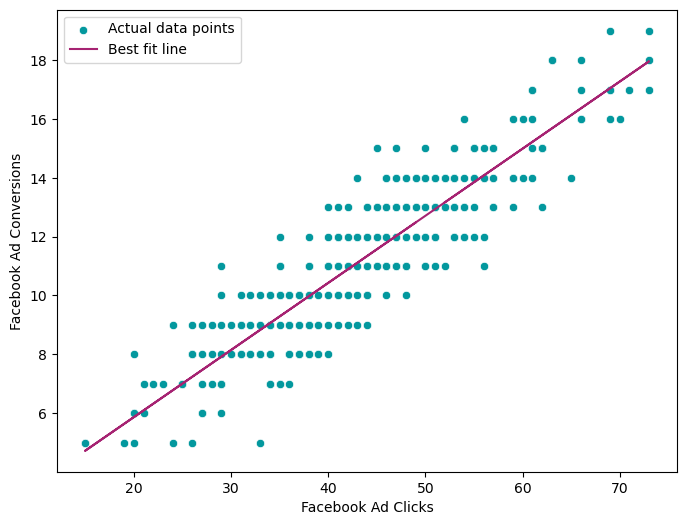

In [38]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=df['Facebook Ad Clicks'],
    y=df['Facebook Ad Conversions'],
    color='#03989E',
    label='Actual data points'
)

plt.plot(
    df['Facebook Ad Clicks'],
    prediction,
    color='#A62372',
    label='Best fit line'
)

plt.legend()
plt.show()

In [39]:
print(
    f'For 50 Clicks, Expected Conversion : '
    f'{round(reg_model.predict([[50]])[0][0], 2)}'
)

print(
    f'For 80 Clicks, Expected Conversion : '
    f'{round(reg_model.predict([[80]])[0][0], 2)}'
)

For 50 Clicks, Expected Conversion : 12.71
For 80 Clicks, Expected Conversion : 19.55


In [43]:
from IPython.display import Markdown, display

display(Markdown("""
### Linear Regression – Facebook Ads Conversion Prediction

- The Linear Regression model achieved an **R-squared score of 76.35%**, indicating that approximately 76.35% of the variation in Facebook ad conversions is explained by Facebook ad clicks.
- This suggests a reasonably strong relationship between ad clicks and conversions.

### Business Insights

- Predict the expected number of conversions based on Facebook ad clicks.
- Set realistic campaign targets and plan advertising budgets.
- Evaluate campaign performance and identify opportunities to improve conversion rates.
- Optimize Facebook advertising strategies to improve marketing efficiency.

### Conclusion

Linear Regression provides a useful predictive approach to understanding the relationship between Facebook ad clicks and conversions, helping businesses make informed marketing decisions.
"""))


### Linear Regression – Facebook Ads Conversion Prediction

- The Linear Regression model achieved an **R-squared score of 76.35%**, indicating that approximately 76.35% of the variation in Facebook ad conversions is explained by Facebook ad clicks.
- This suggests a reasonably strong relationship between ad clicks and conversions.

### Business Insights

- Predict the expected number of conversions based on Facebook ad clicks.
- Set realistic campaign targets and plan advertising budgets.
- Evaluate campaign performance and identify opportunities to improve conversion rates.
- Optimize Facebook advertising strategies to improve marketing efficiency.

### Conclusion

Linear Regression provides a useful predictive approach to understanding the relationship between Facebook ad clicks and conversions, helping businesses make informed marketing decisions.
